<a href="https://colab.research.google.com/github/DMRF-FIME/AF3-Pendulo-Robot/blob/main/AF4_robot_2GDL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

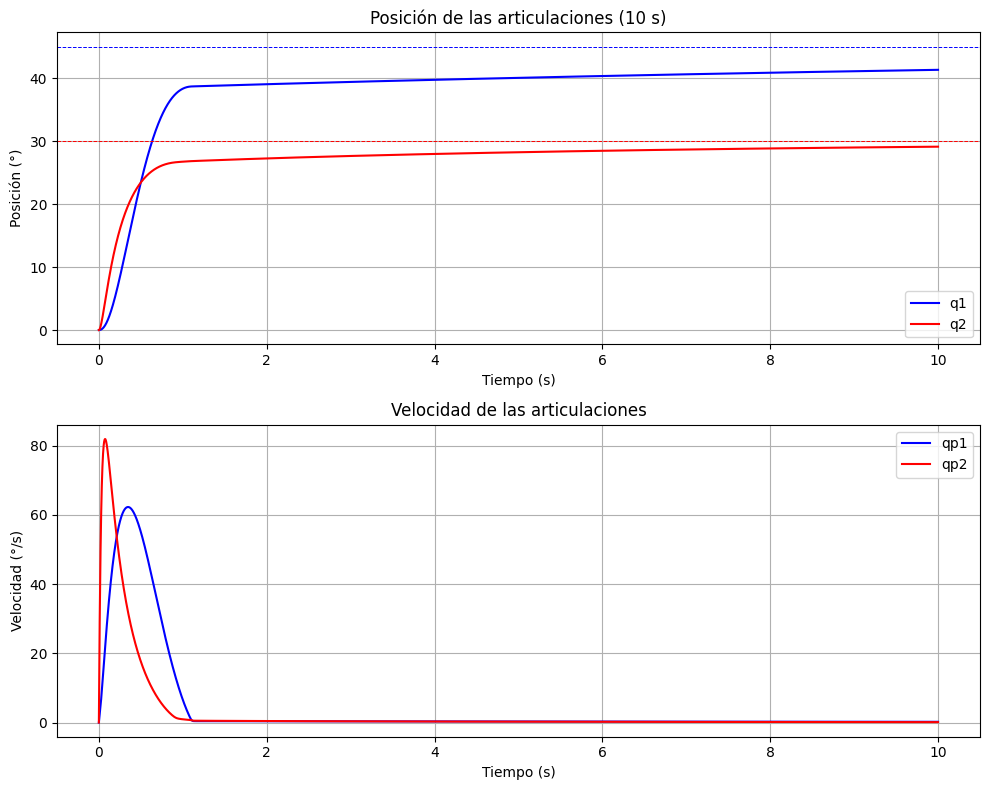

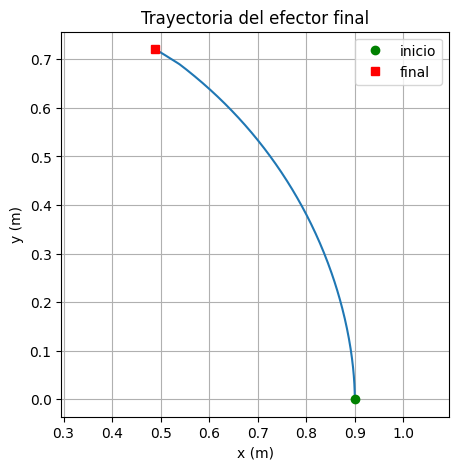

q1 final = 41.3 grados
q2 final = 29.102 grados


In [1]:
# -----------------------------------------------------------------
# SIMULACIÓN DE UN ROBOT MANIPULADOR PLANAR DE 2 GDL
# Ecuación: tau = M(q)*qpp + c(q,qp)*qp + g(q) + f(qp)
# -----------------------------------------------------------------

import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# -----------------------------------------------------------------
# 1. Ecuación dinámica del robot
# -----------------------------------------------------------------
def f(t, x):
    # Parámetros del robot (tabla 5.1)
    m1, m2 = 23.902, 3.88        # masas (kg)
    l1, l2 = 0.45, 0.45          # longitudes (m)
    lc1, lc2 = 0.091, 0.048      # distancia al centro de masa (m)
    I1, I2 = 1.266, 0.093        # inercias (kg m^2)
    b1, b2 = 2.288, 0.175        # fricción viscosa (Nms/rad)
    fc1, fc2 = 5.3, 1.1          # fricción de Coulomb (Nm)
    g = 9.81                     # gravedad (m/s^2)

    # Vector de estados
    q1, q2, qp1, qp2 = x
    q = np.array([q1, q2])
    qp = np.array([qp1, qp2])

    # Matriz de inercia M(q)
    M11 = m1*lc1**2 + m2*(l1**2 + lc2**2 + 2*l1*lc2*np.cos(q2)) + I1 + I2
    M12 = m2*(lc2**2 + l1*lc2*np.cos(q2)) + I2
    M22 = m2*lc2**2 + I2
    M = np.array([[M11, M12],
                  [M12, M22]])

    # Matriz de Coriolis c(q, qp)
    h = m2*l1*lc2*np.sin(q2)
    c = np.array([[-h*qp2, -h*(qp1 + qp2)],
                  [ h*qp1,  0]])

    # Vector de gravedad g(q)
    g2 = m2*lc2*g*np.cos(q1 + q2)
    g1 = (m1*lc1 + m2*l1)*g*np.cos(q1) + g2
    G = np.array([g1, g2])

    # Vector de fricción f(qp): viscosa + Coulomb
    # tanh(100*qp) es una aproximación suave de sign(qp)
    F = np.array([b1*qp1 + fc1*np.tanh(100*qp1),
                  b2*qp2 + fc2*np.tanh(100*qp2)])

    # Pares de los motores
    tau_motor = tau(q, qp, G)

    # Aceleraciones (se despeja qpp de la ecuación del robot)
    qpp = np.linalg.inv(M) @ (tau_motor - c @ qp - G - F)

    # Derivada del vector de estados
    return [qp1, qp2, qpp[0], qpp[1]]

# --- Pares de los motores: PD + compensación de gravedad ---
def tau(q, qp, G):
    q_deseada = np.array([np.pi/4, np.pi/6])   # 45° y 30°
    Kp = np.diag([30, 15])
    Kd = np.diag([8, 3])
    return Kp @ (q_deseada - q) - Kd @ qp + G

# -----------------------------------------------------------------
# 2. Simulación (10 segundos)
# -----------------------------------------------------------------
ti = 0.0
tf = 10.0
h = 0.0025
ts = np.arange(ti, tf + h, h)

x0 = [0.0, 0.0, 0.0, 0.0]     # q1, q2, qp1, qp2

sol = solve_ivp(f, [ti, tf], x0, t_eval=ts, rtol=1e-8, atol=1e-10)

t = sol.t
q1 = np.rad2deg(sol.y[0])
q2 = np.rad2deg(sol.y[1])
qp1 = np.rad2deg(sol.y[2])
qp2 = np.rad2deg(sol.y[3])

# -----------------------------------------------------------------
# 3. Gráficas
# -----------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

ax1.plot(t, q1, 'b-', label='q1')
ax1.plot(t, q2, 'r-', label='q2')
ax1.axhline(45, color='b', linestyle='--', linewidth=0.7)
ax1.axhline(30, color='r', linestyle='--', linewidth=0.7)
ax1.set_xlabel('Tiempo (s)')
ax1.set_ylabel('Posición (°)')
ax1.set_title('Posición de las articulaciones (10 s)')
ax1.legend()
ax1.grid(True)

ax2.plot(t, qp1, 'b-', label='qp1')
ax2.plot(t, qp2, 'r-', label='qp2')
ax2.set_xlabel('Tiempo (s)')
ax2.set_ylabel('Velocidad (°/s)')
ax2.set_title('Velocidad de las articulaciones')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# Trayectoria del efector final
l1, l2 = 0.45, 0.45
x_ef = l1*np.cos(sol.y[0]) + l2*np.cos(sol.y[0] + sol.y[1])
y_ef = l1*np.sin(sol.y[0]) + l2*np.sin(sol.y[0] + sol.y[1])

plt.figure(figsize=(5, 5))
plt.plot(x_ef, y_ef)
plt.plot(x_ef[0], y_ef[0], 'go', label='inicio')
plt.plot(x_ef[-1], y_ef[-1], 'rs', label='final')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Trayectoria del efector final')
plt.axis('equal')
plt.legend()
plt.grid(True)
plt.show()

print("q1 final =", round(q1[-1], 3), "grados")
print("q2 final =", round(q2[-1], 3), "grados")